# A2: Who should get the email? Uplift targeting on a 64,000-customer randomised test

**Business question:** Should we send the men's email, the women's email, or nothing, and to which customers, to make the most extra profit?

**Data:** Kevin Hillstrom's MineThatData email challenge. 64,000 customers were randomly put into 3 groups (men's email, women's email, no email). We then watched them for 2 weeks (`visit`, `conversion`, `spend`).

**Tools:** pandas, numpy, matplotlib, seaborn. scikit-learn only in Step 4 for the model.

In [1]:
import pandas as pd

path = "Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv"   # file sits next to this notebook
df = pd.read_csv(path)

print(df.shape)
print(df["segment"].value_counts())

(64000, 12)
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


In [2]:
summary = df.groupby("segment").agg(
    customers=("segment", "count"),
    conversion_rate=("conversion", "mean"),
    avg_spend=("spend", "mean")
)
print(summary)

               customers  conversion_rate  avg_spend
segment                                             
Mens E-Mail        21307         0.012531   1.422617
No E-Mail          21306         0.005726   0.652789
Womens E-Mail      21387         0.008837   1.077202


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
np.random.seed(42)   # makes the random parts give the same answer every time you run

## Step 1: Was the test fair? (Randomisation check)

If customers were really split at random, the 3 groups should be about the same size, and they should look alike (same recency, same past spend, and so on). If not, any difference we find later could be because of *who* got the email, not the email itself.

**1a. Group sizes.** With 64,000 customers, a perfect split would be 21,333 per group.

In [4]:
counts = df["segment"].value_counts()

total = len(df)
expected = total / 3
print("Expected per group if perfectly equal:", round(expected, 1))

for group in counts.index:
    actual = counts[group]
    difference = actual - expected
    percent_off = (difference / expected) * 100
    print(group, "| actual:", actual, "| difference:", round(difference, 1), "| percent off:", round(percent_off, 2))

Expected per group if perfectly equal: 21333.3
Womens E-Mail | actual: 21387 | difference: 53.7 | percent off: 0.25
Mens E-Mail | actual: 21307 | difference: -26.3 | percent off: -0.12
No E-Mail | actual: 21306 | difference: -27.3 | percent off: -0.13


**1b. Sample-ratio test (chi-square, done by hand).** For each group we compute `(actual - expected)² / expected` and add them up. A big number means the split looks suspicious. For 3 groups, anything **below 5.99** is a normal random split.

In [5]:
chi_square = 0
for group in counts.index:
    chi_square = chi_square + (counts[group] - expected) ** 2 / expected

print("Chi-square value:", round(chi_square, 2))
print("Suspicious only if above 5.99 (3 groups, 5% level)")
if chi_square < 5.99:
    print("PASS: group sizes look like a normal random split")
else:
    print("FAIL: group sizes look unusual, investigate")

Chi-square value: 0.2
Suspicious only if above 5.99 (3 groups, 5% level)
PASS: group sizes look like a normal random split


**1c. Do the groups look alike?** We compare the average customer in each group. The last table shows the gap versus the No E-Mail group measured in standard deviations. A common rule of thumb is that anything **under 0.1** means the groups are well balanced.

In [6]:
balance_columns = ["recency", "history", "mens", "womens", "newbie"]
balance = df.groupby("segment")[balance_columns].mean().round(3)
print(balance)

spread = df[balance_columns].std()
for arm_name in ["Mens E-Mail", "Womens E-Mail"]:
    gap = (balance.loc[arm_name] - balance.loc["No E-Mail"]) / spread
    print()
    print(arm_name, "vs No E-Mail (gap in standard deviations):")
    print(gap.round(3))

               recency  history   mens  womens  newbie
segment                                               
Mens E-Mail      5.774  242.836  0.551   0.551   0.502
No E-Mail        5.750  240.883  0.553   0.548   0.502
Womens E-Mail    5.768  242.537  0.549   0.550   0.503

Mens E-Mail vs No E-Mail (gap in standard deviations):
recency    0.007
history    0.008
mens      -0.004
womens     0.006
newbie     0.000
dtype: float64

Womens E-Mail vs No E-Mail (gap in standard deviations):
recency    0.005
history    0.006
mens      -0.008
womens     0.004
newbie     0.002
dtype: float64


## Step 2: How much did each email lift visits, conversions and spend?

Because the groups were random, the **lift** is simply `average in email group - average in No E-Mail group`.

We give each lift a **95% confidence interval** (a range that likely contains the true lift), in two ways:
- **t-statistic:** lift divided by its noise. Above about 1.96 (or below -1.96) means it is unlikely to be luck.
- **Bootstrap:** we re-draw customers with replacement 2,000 times, and each time we recompute the lift. The middle 95% of those 2,000 answers is the interval.

In [7]:
control = df[df["segment"] == "No E-Mail"]
mens = df[df["segment"] == "Mens E-Mail"]
womens = df[df["segment"] == "Womens E-Mail"]

def bootstrap_ci(treated_values, control_values, n_rounds=2000):
    differences = []
    for i in range(n_rounds):
        t_sample = np.random.choice(treated_values, size=len(treated_values), replace=True)
        c_sample = np.random.choice(control_values, size=len(control_values), replace=True)
        differences.append(t_sample.mean() - c_sample.mean())
    low, high = np.percentile(differences, [2.5, 97.5])
    return low, high

def t_statistic(treated_values, control_values):
    lift = treated_values.mean() - control_values.mean()
    noise = np.sqrt(treated_values.var() / len(treated_values) + control_values.var() / len(control_values))
    return lift / noise

rows = []
for arm_name, arm_data in [("Mens E-Mail", mens), ("Womens E-Mail", womens)]:
    for outcome in ["visit", "conversion", "spend"]:
        t_values = arm_data[outcome].values
        c_values = control[outcome].values
        low, high = bootstrap_ci(t_values, c_values)
        rows.append({
            "arm": arm_name,
            "outcome": outcome,
            "no_email_avg": c_values.mean(),
            "email_avg": t_values.mean(),
            "lift": t_values.mean() - c_values.mean(),
            "ci_low": low,
            "ci_high": high,
            "t_stat": t_statistic(t_values, c_values),
        })

lift_table = pd.DataFrame(rows)
print(lift_table.round(4).to_string(index=False))

          arm    outcome  no_email_avg  email_avg   lift  ci_low  ci_high  t_stat
  Mens E-Mail      visit        0.1062     0.1828 0.0766  0.0700   0.0837 22.6208
  Mens E-Mail conversion        0.0057     0.0125 0.0068  0.0050   0.0086  7.3899
  Mens E-Mail      spend        0.6528     1.4226 0.7698  0.4996   1.0665  5.3003
Womens E-Mail      visit        0.1062     0.1514 0.0452  0.0391   0.0513 13.9851
Womens E-Mail conversion        0.0057     0.0088 0.0031  0.0015   0.0047  3.7817
Womens E-Mail      spend        0.6528     1.0772 0.4244  0.1754   0.6771  3.2564


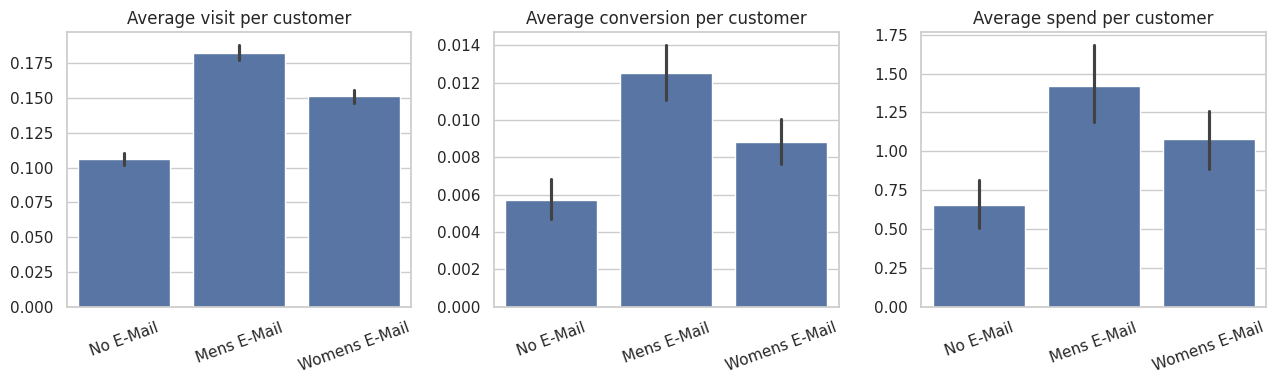

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, outcome in zip(axes, ["visit", "conversion", "spend"]):
    sns.barplot(data=df, x="segment", y=outcome, order=["No E-Mail", "Mens E-Mail", "Womens E-Mail"],
                errorbar=("ci", 95), ax=ax)
    ax.set_title("Average " + outcome + " per customer")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**Power and minimum detectable effect (MDE).** This is the smallest lift this test could reliably detect (80% power, 5% significance). The shortcut formula is `2.8 × sqrt(2 × variance / customers per group)`. If a real lift is smaller than the MDE, this experiment would probably miss it.

In [9]:
n_per_group = len(control)
for outcome in ["visit", "conversion", "spend"]:
    variance = control[outcome].var()
    mde = 2.8 * np.sqrt(2 * variance / n_per_group)
    print(outcome, "| no-email average:", round(control[outcome].mean(), 4), "| MDE:", round(mde, 4))

visit | no-email average: 0.1062 | MDE: 0.0084
conversion | no-email average: 0.0057 | MDE: 0.002
spend | no-email average: 0.6528 | MDE: 0.3144


## Step 3: Which kinds of customers does the email help most?

We split customers into segments (recency, past spend, channel, new vs returning, area), and in each segment we measure the lift in **spend per customer**. (We tried visits first, but the email lifts visits in every single segment, so the correction would have nothing to do. Spend is noisier, which makes it the more honest test.)

**Warning (multiple comparisons):** if you run about 40 tests, around 2 will look "significant" by pure luck at the 5% level. So we correct the p-values with the **Benjamini-Hochberg** method. It keeps the expected share of false alarms at 5%.

The p-values come from a **permutation test**: shuffle the email/no-email labels at random 2,000 times, and count how often luck alone gives a gap as big as the real one.

In [10]:
df["recency_group"] = pd.cut(df["recency"], bins=[0, 3, 6, 9, 12], labels=["1-3", "4-6", "7-9", "10-12"])
segment_columns = ["recency_group", "history_segment", "channel", "newbie", "zip_code"]

def permutation_test(outcome, is_treated, n_shuffles=2000):
    real_gap = outcome[is_treated].mean() - outcome[~is_treated].mean()
    count = 0
    for i in range(n_shuffles):
        shuffled = np.random.permutation(is_treated)
        fake_gap = outcome[shuffled].mean() - outcome[~shuffled].mean()
        if abs(fake_gap) >= abs(real_gap):
            count = count + 1
    p_value = (count + 1) / (n_shuffles + 1)
    return real_gap, p_value

def benjamini_hochberg(p_values):
    p_values = np.array(p_values)
    m = len(p_values)
    order = np.argsort(p_values)
    adjusted_sorted = p_values[order] * m / np.arange(1, m + 1)
    adjusted_sorted = np.minimum.accumulate(adjusted_sorted[::-1])[::-1]   # keep the order sensible
    adjusted = np.zeros(m)
    adjusted[order] = np.minimum(adjusted_sorted, 1)
    return adjusted

segment_rows = []
for arm_name in ["Mens E-Mail", "Womens E-Mail"]:
    for column in segment_columns:
        for level in df[column].dropna().unique():
            part = df[(df[column] == level) & (df["segment"].isin([arm_name, "No E-Mail"]))]
            outcome = part["spend"].values
            is_treated = (part["segment"] == arm_name).values
            gap, p = permutation_test(outcome, is_treated)
            segment_rows.append({"arm": arm_name, "segment_type": column, "segment": str(level),
                                 "customers": len(part), "spend_lift": gap, "p_value": p})

segment_table = pd.DataFrame(segment_rows)
segment_table["adjusted_p"] = benjamini_hochberg(segment_table["p_value"])

print("Tests run:", len(segment_table))
print("Significant before correction (p < 0.05):", (segment_table["p_value"] < 0.05).sum())
print("Significant after correction  (adjusted p < 0.05):", (segment_table["adjusted_p"] < 0.05).sum())
print()
print(segment_table.sort_values("adjusted_p").head(10).round(4).to_string(index=False))

Tests run: 38
Significant before correction (p < 0.05): 25
Significant after correction  (adjusted p < 0.05): 22

          arm    segment_type        segment  customers  spend_lift  p_value  adjusted_p
  Mens E-Mail          newbie              1      21381      0.9600   0.0005      0.0063
  Mens E-Mail        zip_code      Surburban      19126      0.8038   0.0005      0.0063
Womens E-Mail          newbie              1      21458      0.7323   0.0005      0.0063
  Mens E-Mail         channel            Web      18863      0.8504   0.0010      0.0076
  Mens E-Mail   recency_group            1-3      14907      1.0476   0.0010      0.0076
Womens E-Mail        zip_code          Urban      17098      0.6691   0.0015      0.0095
  Mens E-Mail        zip_code          Urban      17105      0.7365   0.0020      0.0109
  Mens E-Mail         channel   Multichannel       5183      1.2091   0.0030      0.0142
  Mens E-Mail history_segment 2) $100 - $200       9527      0.7042   0.0040      0.0

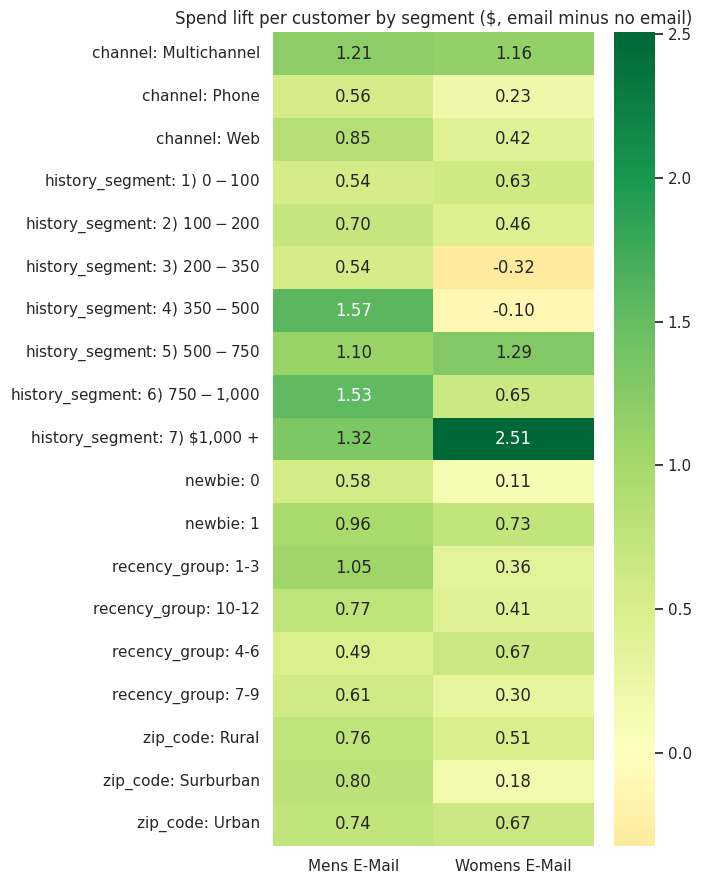

In [11]:
heat = segment_table.copy()
heat["row"] = heat["segment_type"] + ": " + heat["segment"]
heat = heat.pivot(index="row", columns="arm", values="spend_lift")

plt.figure(figsize=(7, 9))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Spend lift per customer by segment ($, email minus no email)")
plt.ylabel("")
plt.xlabel("")
plt.tight_layout()
plt.show()

## Step 4: Build the uplift model

**Idea:** for each customer, predict how much they would spend under each of 3 choices (no email, men's email, women's email). The difference tells us the email's effect on *that* person. That is the **uplift**.

**How:** we train one small model per group (the "T-learner" method). Each model learns spend from customer features (recency, past spend, channel, area, and so on).

**Honest testing:** we use 5-fold cross-validation. The data is cut into 5 parts, and each part is predicted by models that never saw it. So the predictions below are never "memorised" ones.

This is the one place where we use scikit-learn.

In [12]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold

# Turn the text columns (area, channel) into 0/1 columns so the model can read them
X = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=int)
spend = df["spend"].values
arm = df["segment"].values

arms = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
predicted = pd.DataFrame(0.0, index=df.index, columns=arms)

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
for train_rows, test_rows in kfold.split(df):
    for arm_name in arms:
        rows_of_this_arm = train_rows[arm[train_rows] == arm_name]
        model = GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05,
                                          subsample=0.8, min_samples_leaf=100, random_state=42)
        model.fit(X.iloc[rows_of_this_arm], spend[rows_of_this_arm])
        predicted.iloc[test_rows, arms.index(arm_name)] = model.predict(X.iloc[test_rows])

predicted["uplift_mens"] = predicted["Mens E-Mail"] - predicted["No E-Mail"]
predicted["uplift_womens"] = predicted["Womens E-Mail"] - predicted["No E-Mail"]
print(predicted.describe().round(3))

       No E-Mail  Mens E-Mail  Womens E-Mail  uplift_mens  uplift_womens
count  64000.000    64000.000      64000.000    64000.000      64000.000
mean       0.656        1.426          1.078        0.770          0.422
std        0.494        0.860          0.866        0.778          0.875
min       -0.366       -3.024         -3.480       -4.101         -5.873
25%        0.317        0.903          0.693        0.336          0.024
50%        0.578        1.243          0.902        0.663          0.370
75%        0.866        1.728          1.208        1.081          0.716
max        5.647       13.130         14.187       10.766         13.502


**Qini curve: does the model rank customers well?** We sort customers from highest to lowest predicted uplift. Then we walk down the list and track the *extra* spend the email has produced so far. A good model rises fast and then flattens. The dashed line is what random targeting would give.

We also draw a line that ranks by *predicted spend* (the "big spenders first" idea), to check whether uplift really adds anything over simply targeting big spenders. In textbooks the uplift line wins, because big spenders would buy anyway. Look at what *this* data says.

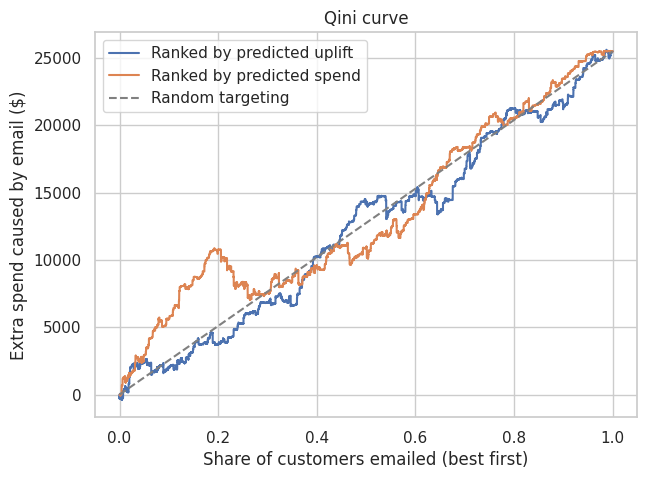

In [13]:
is_emailed = (arm != "No E-Mail")

def qini_curve(score, spend, is_emailed):
    order = np.argsort(-score)
    s = spend[order]
    t = is_emailed[order]
    emailed_spend = np.cumsum(s * t)
    control_spend = np.cumsum(s * ~t)
    emailed_count = np.cumsum(t)
    control_count = np.cumsum(~t)
    scale = emailed_count / np.maximum(control_count, 1)
    extra_spend = emailed_spend - control_spend * scale
    share_targeted = np.arange(1, len(s) + 1) / len(s)
    return share_targeted, extra_spend

best_uplift = predicted[["uplift_mens", "uplift_womens"]].max(axis=1).values
big_spender_score = predicted["No E-Mail"].values

x1, y1 = qini_curve(best_uplift, spend, is_emailed)
x2, y2 = qini_curve(big_spender_score, spend, is_emailed)

plt.figure(figsize=(7, 5))
plt.plot(x1, y1, label="Ranked by predicted uplift")
plt.plot(x2, y2, label="Ranked by predicted spend")
plt.plot([0, 1], [0, y1[-1]], "--", color="gray", label="Random targeting")
plt.xlabel("Share of customers emailed (best first)")
plt.ylabel("Extra spend caused by email ($)")
plt.title("Qini curve")
plt.legend()
plt.show()

## Step 5: Turn it into money

**Assumptions (change them and re-run!):**
- Gross margin is **30%** of spend. We only keep that share of each dollar.
- Each email costs **$0.10** to send.

**Targeting rule:** for each customer, compute `extra spend × margin - email cost` for the men's and the women's email. Send the better one if it is above zero. Otherwise send nothing.

**How we score a rule fairly:** the test was random, so we check customers whose *actual* email matches what the rule would have sent. Their average spend (scaled up by the share of customers in that group) estimates what the rule would earn if applied to everyone. This is called inverse-probability weighting.

In [14]:
shares = pd.Series(arm).value_counts(normalize=True)

def policy_value(chosen_arm, spend, arm):
    # average spend per customer if everyone got the email the rule picked
    value = 0
    for a in arms:
        matches = (chosen_arm == a) & (arm == a)
        value = value + spend[matches].sum() / shares[a]
    return value / len(spend)

def profit_per_1000(chosen_arm, spend, arm, margin, cost):
    value = policy_value(chosen_arm, spend, arm)
    share_emailed = (chosen_arm != "No E-Mail").mean()
    return (value * margin - cost * share_emailed) * 1000

def targeting_rule(margin, cost):
    gain_none = np.zeros(len(df))
    gain_mens = predicted["uplift_mens"].values * margin - cost
    gain_womens = predicted["uplift_womens"].values * margin - cost
    gains = np.column_stack([gain_none, gain_mens, gain_womens])
    best = gains.argmax(axis=1)          # 0 = nobody, 1 = men's, 2 = women's
    return np.array(arms)[best]

margin = 0.30
cost = 0.10

choices = {
    "Email nobody": np.array(["No E-Mail"] * len(df)),
    "Email everyone: men's": np.array(["Mens E-Mail"] * len(df)),
    "Email everyone: women's": np.array(["Womens E-Mail"] * len(df)),
    "Uplift targeting rule": targeting_rule(margin, cost),
}

profit_none = profit_per_1000(choices["Email nobody"], spend, arm, margin, cost)
for name, chosen in choices.items():
    profit = profit_per_1000(chosen, spend, arm, margin, cost)
    sent = (chosen != "No E-Mail").mean() * 100
    print(name.ljust(26), "| emails sent:", str(round(sent, 1)).rjust(5), "% | extra profit per 1,000 customers: $", round(profit - profit_none, 1))

print()
print("Uplift rule picks:")
print(pd.Series(choices["Uplift targeting rule"]).value_counts())

Email nobody               | emails sent:   0.0 % | extra profit per 1,000 customers: $ 0.0
Email everyone: men's      | emails sent: 100.0 % | extra profit per 1,000 customers: $ 130.9
Email everyone: women's    | emails sent: 100.0 % | extra profit per 1,000 customers: $ 27.3
Uplift targeting rule      | emails sent:  83.9 % | extra profit per 1,000 customers: $ 73.3

Uplift rule picks:
Mens E-Mail      36720
Womens E-Mail    16979
No E-Mail        10301
Name: count, dtype: int64


**How sure are we?** Customers are re-drawn with replacement 500 times. Each time we recompute the profit of the uplift rule and of the best mail-everyone option.

In [15]:
rule_choice = choices["Uplift targeting rule"]
mens_all = choices["Email everyone: men's"]
none_all = choices["Email nobody"]

gain_rule = []
gain_mens_all = []
gain_difference = []
for i in range(500):
    pick = np.random.randint(0, len(df), size=len(df))
    s, a = spend[pick], arm[pick]
    base = profit_per_1000(none_all[pick], s, a, margin, cost)
    rule_gain = profit_per_1000(rule_choice[pick], s, a, margin, cost) - base
    mens_gain = profit_per_1000(mens_all[pick], s, a, margin, cost) - base
    gain_rule.append(rule_gain)
    gain_mens_all.append(mens_gain)
    gain_difference.append(rule_gain - mens_gain)

print("Uplift rule gain per 1,000: $", round(np.mean(gain_rule), 1), "| 95% range:", np.round(np.percentile(gain_rule, [2.5, 97.5]), 1))
print("Mail-all (men's) gain per 1,000: $", round(np.mean(gain_mens_all), 1), "| 95% range:", np.round(np.percentile(gain_mens_all, [2.5, 97.5]), 1))
print("Rule minus mail-all: $", round(np.mean(gain_difference), 1), "| 95% range:", np.round(np.percentile(gain_difference, [2.5, 97.5]), 1))

Uplift rule gain per 1,000: $ 72.3 | 95% range: [ -0.3 148.1]
Mail-all (men's) gain per 1,000: $ 128.5 | 95% range: [ 41.9 210.6]
Rule minus mail-all: $ -56.2 | 95% range: [-119.2    4.5]


**Sensitivity table.** Margin and email cost are our own assumptions, so we test what happens if they are wrong. Each cell shows the **extra profit per 1,000 customers** of the uplift rule, minus the best "email everyone" option.

In [16]:
margins = [0.2, 0.3, 0.4, 0.5]
costs = [0.05, 0.10, 0.20, 0.50]

table = pd.DataFrame(index=["margin " + str(int(m * 100)) + "%" for m in margins],
                     columns=["cost $" + str(c) for c in costs], dtype=float)
for m in margins:
    for c in costs:
        rule = profit_per_1000(targeting_rule(m, c), spend, arm, m, c)
        mail_men = profit_per_1000(mens_all, spend, arm, m, c)
        mail_women = profit_per_1000(choices["Email everyone: women's"], spend, arm, m, c)
        none = profit_per_1000(none_all, spend, arm, m, c)
        best_mail_all = max(mail_men, mail_women, none)    # "none" counts too, in case emailing everyone loses money
        table.loc["margin " + str(int(m * 100)) + "%", "cost $" + str(c)] = rule - best_mail_all

print(table.round(1))

            cost $0.05  cost $0.1  cost $0.2  cost $0.5
margin 20%       -39.6      -43.0      -35.8       -7.1
margin 30%       -59.4      -57.6      -28.1      -41.0
margin 40%       -69.2      -79.3      -86.0      -59.6
margin 50%       -87.2     -107.2      -78.7      -89.6


## Results and recommendation

**1. The test was fair.** Group sizes were within 0.25% of a perfect split (chi-square 0.2, far below the 5.99 cut-off), and the groups were nearly identical on recency, past spend and customer type (every gap was under 0.01 standard deviations).

**2. Both emails worked, and the men's email worked better.**

| | Visit lift | Conversion lift | Spend lift per customer (95% CI) |
|---|---|---|---|
| Men's email | +7.7 points (10.6% → 18.3%) | +0.68 points | **+$0.77** ($0.50 to $1.07) |
| Women's email | +4.5 points | +0.31 points | **+$0.42** ($0.18 to $0.68) |

The smallest spend lift this test could reliably detect was about $0.31. The $0.35 gap between the men's and women's email is right at that limit, so "men's beats women's" is likely but not proven for spend.

**3. The email helps almost everyone.** Across 38 customer segments, 25 looked significant for spend lift, and 22 still did after the multiple-comparison correction. Without the correction we would have trusted 3 false alarms.

**4. The uplift model did NOT beat "email everyone with the men's email".**

At a 30% margin and $0.10 per email, extra profit per 1,000 customers was:

| Option | Extra profit per 1,000 customers |
|---|---|
| Email nobody | $0 |
| Email everyone: women's | $27 |
| **Email everyone: men's** | **$131** (95% range about $42 to $211) |
| Uplift targeting rule | $73 |

The uplift rule came out about $56 per 1,000 *below* mailing everyone with the men's email (95% range -$119 to +$5), and it stayed below in every margin and cost combination in the sensitivity table. On the Qini chart, ranking by predicted spend ("big spenders first") was not worse than ranking by uplift.

**Why this happens:**
- The men's email lifts spend for almost every kind of customer, so there are few people worth skipping.
- An email costs $0.10, while the average extra gross profit is about $0.23 per customer, so mailing everyone is already worth it.
- Only about 0.9% of customers buy in 2 weeks, so predicted spend per customer is very noisy. A model that tries to pick winners ends up skipping some people who would have paid off.

**Recommendation:** under these assumptions, send the men's email to everyone and keep a small holdout group that gets no email, so the lift can keep being measured. Targeting would only start to pay off if emails got much more expensive or if we had far more data.

**Limits:** 2 weeks of data only, unsubscribes and complaints are not in the data, and margin and cost are our own assumptions. Other model set-ups I tried outside this notebook (simpler, more regularised, and one built on visits) gave $89 to $121 per 1,000 customers. None of them beat $131.